# Berlin housing market 2020–2026: walkthrough

A guided tour of the pipeline's outputs. Run `make run` first so that
`data/processed/` is populated; this notebook only reads those outputs and
reuses functions from `src/`, so the numbers match the pipeline exactly.

1. Data at a glance
2. Spatial price structure
3. Validating the computed transit distance
4. Policy shocks and the citywide index
5. Buy vs rent
6. Price model performance

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.config import PROC_DIR
from src.policy_analysis import EVENTS

# src modules select the non-interactive Agg backend for the pipeline;
# switch back to inline rendering for the notebook
%matplotlib inline
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.dpi"] = 110

sales = pd.read_csv(PROC_DIR / "sales_clean.csv", parse_dates=["date_listed"])
rentals = pd.read_csv(PROC_DIR / "rentals_clean.csv", parse_dates=["date_listed"])
index = pd.read_csv(PROC_DIR / "citywide_monthly_index.csv", parse_dates=["date"])
yields = pd.read_csv(PROC_DIR / "ortsteil_yields.csv")

## 1. Data at a glance

In [2]:
pd.DataFrame(
    {
        "rows": [len(sales), len(rentals)],
        "Ortsteile": [sales.ortsteil.nunique(), rentals.ortsteil.nunique()],
        "first listing": [sales.date_listed.min().date(), rentals.date_listed.min().date()],
        "last listing": [sales.date_listed.max().date(), rentals.date_listed.max().date()],
    },
    index=["sales", "rentals"],
)

,rows,Ortsteile,first listing,last listing
sales,49000,82,2020-01-01,2026-04-29
rentals,29401,82,2020-01-01,2026-04-29


In [3]:
sales[
    [
        "price_eur",
        "price_per_m2_eur",
        "area_m2",
        "rooms",
        "year_built",
        "computed_dist_nearest_station_km",
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
price_eur,"49,000.00","302,459.02","233,422.92","27,000.00","143,000.00","232,000.00","388,000.00","2,283,000.00"
price_per_m2_eur,"49,000.00","3,876.14","1,770.87","1,316.00","2,544.00","3,434.00","4,822.00","10,100.00"
area_m2,"49,000.00",75.37,37.52,20.00,48.10,68.30,94.40,294.10
rooms,"49,000.00",2.52,1.14,1.00,2.00,2.00,3.00,5.00
year_built,"49,000.00","1,960.96",39.79,"1,880.00","1,930.00","1,966.00","1,993.00","2,024.00"
computed_dist_nearest_station_km,"49,000.00",3.02,3.01,0.01,0.72,1.72,4.66,15.02


## 2. Spatial price structure

Median sale price per m² by Bezirk. The spread between the most and least
expensive districts is roughly 3×.

,median,size
bezirk,,
Friedrichshain-Kreuzberg,"6,076.00",1184
Mitte,"5,803.50",3416
Charlottenburg-Wilmersdorf,"5,797.00",4097
Steglitz-Zehlendorf,"5,027.50",4226
Tempelhof-Schöneberg,"3,792.00",3585
Pankow,"3,522.00",4793
Treptow-Köpenick,"3,297.00",5937
Neukölln,"3,083.50",3020
Reinickendorf,"2,983.00",6820


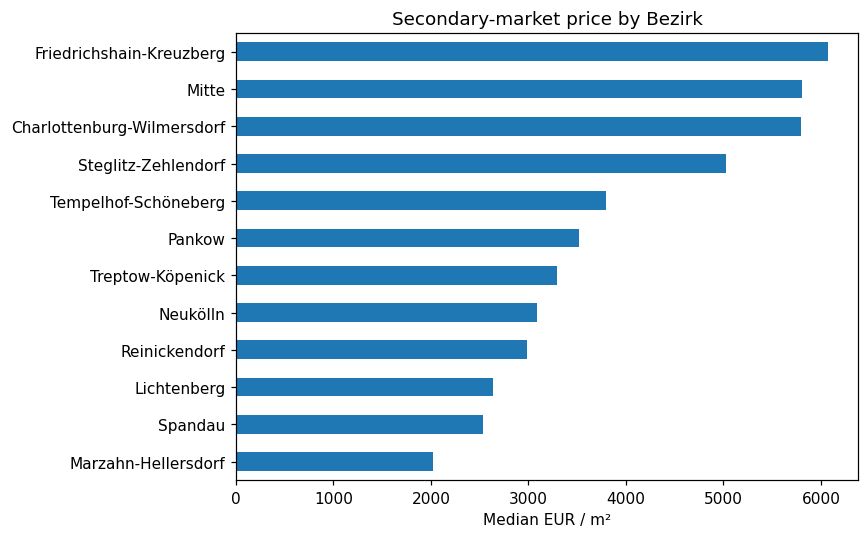

In [4]:
by_bezirk = (
    sales.groupby("bezirk")["price_per_m2_eur"].agg(["median", "size"]).sort_values("median")
)
ax = by_bezirk["median"].plot.barh(figsize=(8, 5), color="#1f77b4")
ax.set_xlabel("Median EUR / m²")
ax.set_ylabel("")
ax.set_title("Secondary-market price by Bezirk")
plt.tight_layout()
by_bezirk.sort_values("median", ascending=False)

Spearman rho = -0.52


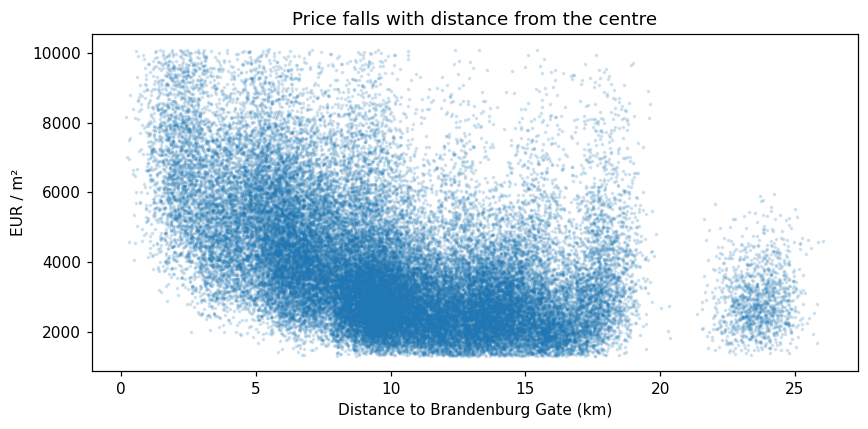

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(sales["to_brandenburg_gate_km"], sales["price_per_m2_eur"], s=2, alpha=0.15)
ax.set_xlabel("Distance to Brandenburg Gate (km)")
ax.set_ylabel("EUR / m²")
ax.set_title("Price falls with distance from the centre")
plt.tight_layout()
rho = sales["to_brandenburg_gate_km"].corr(sales["price_per_m2_eur"], method="spearman")
print(f"Spearman rho = {rho:.2f}")

## 3. Validating the computed transit distance

The transform stage computes straight-line distance to the nearest of the
135 real stations with a KD-tree in EPSG:25833, independently of the
dataset's own `transit_distance_min` column. If both describe the same
geography, they should rise together.

Pearson r = 0.738


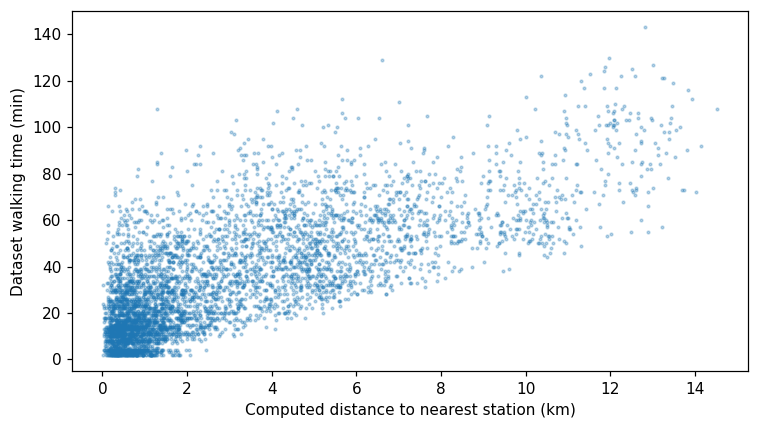

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
sample = sales.sample(5000, random_state=42)
ax.scatter(
    sample["computed_dist_nearest_station_km"], sample["transit_distance_min"], s=3, alpha=0.3
)
ax.set_xlabel("Computed distance to nearest station (km)")
ax.set_ylabel("Dataset walking time (min)")
plt.tight_layout()
r = sales["computed_dist_nearest_station_km"].corr(sales["transit_distance_min"])
print(f"Pearson r = {r:.3f}")

## 4. Policy shocks and the citywide index

The citywide index is a listing-count-weighted mean of the 82 Ortsteil
series (`policy_analysis.weighted_monthly_index`).

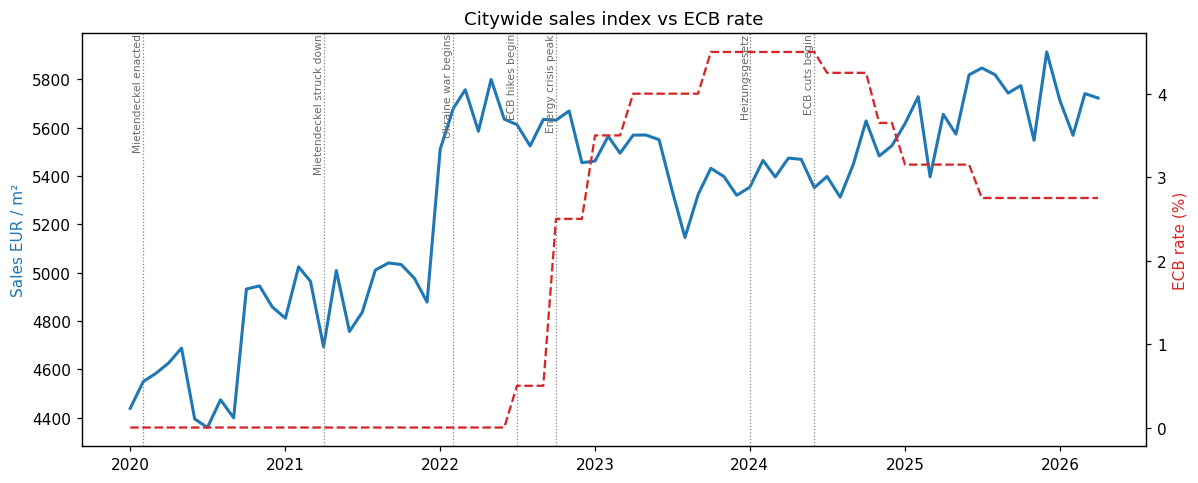

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(index["date"], index["sales_eur_m2"], color="#1f77b4", lw=2)
ax.set_ylabel("Sales EUR / m²", color="#1f77b4")
ax2 = ax.twinx()
ax2.plot(index["date"], index["ecb_rate_pct"], color="#d62728", ls="--")
ax2.set_ylabel("ECB rate (%)", color="#d62728")
for ym, label in EVENTS:
    d = pd.Timestamp(ym + "-01")
    ax.axvline(d, color="gray", ls=":", lw=0.8)
    ax.text(
        d, ax.get_ylim()[1], label, rotation=90, fontsize=7, va="top", ha="right", color="dimgray"
    )
ax.set_title("Citywide sales index vs ECB rate")
plt.tight_layout()

In [8]:
# full calendar years only (2026 is partial)
yoy = index.set_index("date")[["sales_eur_m2", "rent_eur_m2"]].resample("YE").mean().loc[:"2025"]
(yoy.pct_change() * 100).rename(columns=lambda c: c + " YoY %").dropna()

,sales_eur_m2 YoY %,rent_eur_m2 YoY %
date,,
2021-12-31,6.85,6.24
2022-12-31,14.34,12.76
2023-12-31,-3.44,6.83
2024-12-31,0.20,5.37
2025-12-31,4.79,6.27


## 5. Buy vs rent

Gross yield = annual Kaltmiete per m² / sale price per m². Per-Ortsteil
figures use listing-level medians over the last 12 months (see
`yield_analysis.py` for why the Kiez series can't be used for this).

In [9]:
pd.concat([yields.head(5), yields.tail(5)])[
    [
        "ortsteil",
        "bezirk",
        "sales_eur_m2",
        "kaltmiete_eur_m2_month",
        "gross_yield_pct",
        "price_to_rent",
    ]
]

,ortsteil,bezirk,sales_eur_m2,kaltmiete_eur_m2_month,gross_yield_pct,price_to_rent
0,Müggelheim,Treptow-Köpenick,"2,706.00",11.34,5.03,19.90
1,Schmöckwitz,Treptow-Köpenick,"3,081.00",12.72,4.95,20.20
2,Rudow,Neukölln,"2,946.00",12.06,4.91,20.40
3,Wannsee,Steglitz-Zehlendorf,"5,468.00",21.69,4.76,21.00
4,Nikolassee,Steglitz-Zehlendorf,"5,456.00",21.15,4.65,21.50
77,Buckow,Neukölln,"3,185.00",9.74,3.67,27.30
78,Tiergarten,Mitte,"7,809.00",23.76,3.65,27.40
79,Wilmersdorf,Charlottenburg-Wilmersdorf,"6,769.00",20.44,3.62,27.60
80,Mitte (Ort),Mitte,"7,669.00",22.88,3.58,27.90
81,Tempelhof,Tempelhof-Schöneberg,"4,146.00",12.33,3.57,28.00


corr = -0.47


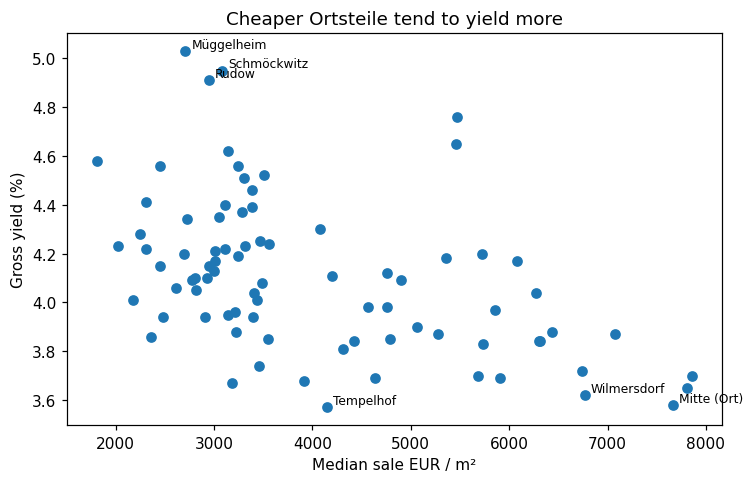

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(yields["sales_eur_m2"], yields["gross_yield_pct"])
for _, r in pd.concat([yields.head(3), yields.tail(3)]).iterrows():
    ax.annotate(
        r["ortsteil"],
        (r["sales_eur_m2"], r["gross_yield_pct"]),
        fontsize=8,
        xytext=(4, 2),
        textcoords="offset points",
    )
ax.set_xlabel("Median sale EUR / m²")
ax.set_ylabel("Gross yield (%)")
ax.set_title("Cheaper Ortsteile tend to yield more")
plt.tight_layout()
print(f"corr = {yields['sales_eur_m2'].corr(yields['gross_yield_pct']):.2f}")

## 6. Price model performance

In [11]:
metrics = json.loads((PROC_DIR / "model_metrics.json").read_text())
frames = []
for view, rows in metrics.items():
    df = pd.DataFrame(rows)
    df.insert(0, "evaluation", view)
    frames.append(df)
pd.concat(frames, ignore_index=True)[
    ["evaluation", "model", "rmse_eur", "rmse_eur_mean", "rmse_eur_std", "r2", "r2_mean"]
]

,evaluation,model,rmse_eur,rmse_eur_mean,rmse_eur_std,r2,r2_mean
0,holdout,LinearRegression,"99,186.00",NaN,NaN,0.82,NaN
1,holdout,RandomForest,"77,081.00",NaN,NaN,0.89,NaN
2,holdout,HistGradientBoosting,"57,250.00",NaN,NaN,0.94,NaN
3,cross_validation,LinearRegression,NaN,"98,954.00",894.00,NaN,0.82
4,cross_validation,RandomForest,NaN,"78,184.00","1,575.00",NaN,0.89
5,cross_validation,HistGradientBoosting,NaN,"57,586.00","1,082.00",NaN,0.94
6,temporal_holdout,LinearRegression,"103,180.00",NaN,NaN,0.82,NaN
7,temporal_holdout,RandomForest,"81,902.00",NaN,NaN,0.89,NaN
8,temporal_holdout,HistGradientBoosting,"60,450.00",NaN,NaN,0.94,NaN


**Takeaways**

- Gradient boosting is the strongest model on all three evaluation views,
  and the out-of-time R² matches the random-split R², so it generalises
  forward in time rather than memorising a market regime.
- Location (Bezirk, distance to centre) is the second-largest driver after
  living space; transit distance adds a smaller but consistent effect.
- Higher-priced Ortsteile tend to have lower gross yields (r ≈ −0.47):
  buyers there pay more per euro of rent, consistent with pricing in
  amenity or expected appreciation rather than rental income.